# 1. EDA and preprocessing
**Goal:** understand the data before modelling. Run `python -m src.train` first for the saved figures; this notebook only reads files.

In [1]:
from pathlib import Path
import json, pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
ROOT = Path.cwd() if (Path.cwd()/'data').exists() else Path.cwd().parent
RES = ROOT/'results'; sns.set_theme(style='whitegrid')
df = pd.read_csv(ROOT/'data'/'phishing.csv')
print(df.shape, 'missing:', df.isna().sum().sum(), 'duplicates:', df.duplicated().sum())
df.head()

(11055, 31) missing: 0 duplicates: 5206


,having_ip_address,url_length,shortining_service,having_at_symbol,double_slash_redirecting,prefix_suffix,having_sub_domain,sslfinal_state,domain_registration_length,favicon,...,popupwindow,iframe,age_of_domain,dnsrecord,web_traffic,page_rank,google_index,links_pointing_to_page,statistical_report,Result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


## Duplicates
About 47% of the raw rows are exact copies. If left in, copies land in both train and test and inflate accuracy, so we remove them **before** splitting.

11055 -> 5849


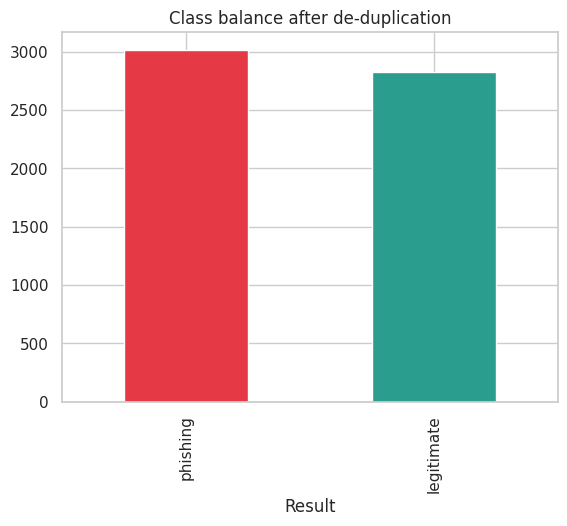

In [2]:
d = df.drop_duplicates().reset_index(drop=True)
print(len(df),'->',len(d))
d['Result'].value_counts().rename({-1:'phishing',1:'legitimate'}).plot(kind='bar', color=['#e63946','#2a9d8f'], title='Class balance after de-duplication')
plt.show()

**Observation:** after cleaning, classes are nearly balanced (≈ 52% phishing / 48% legitimate), so accuracy is a fair headline metric; we still report phishing-class recall and F1.

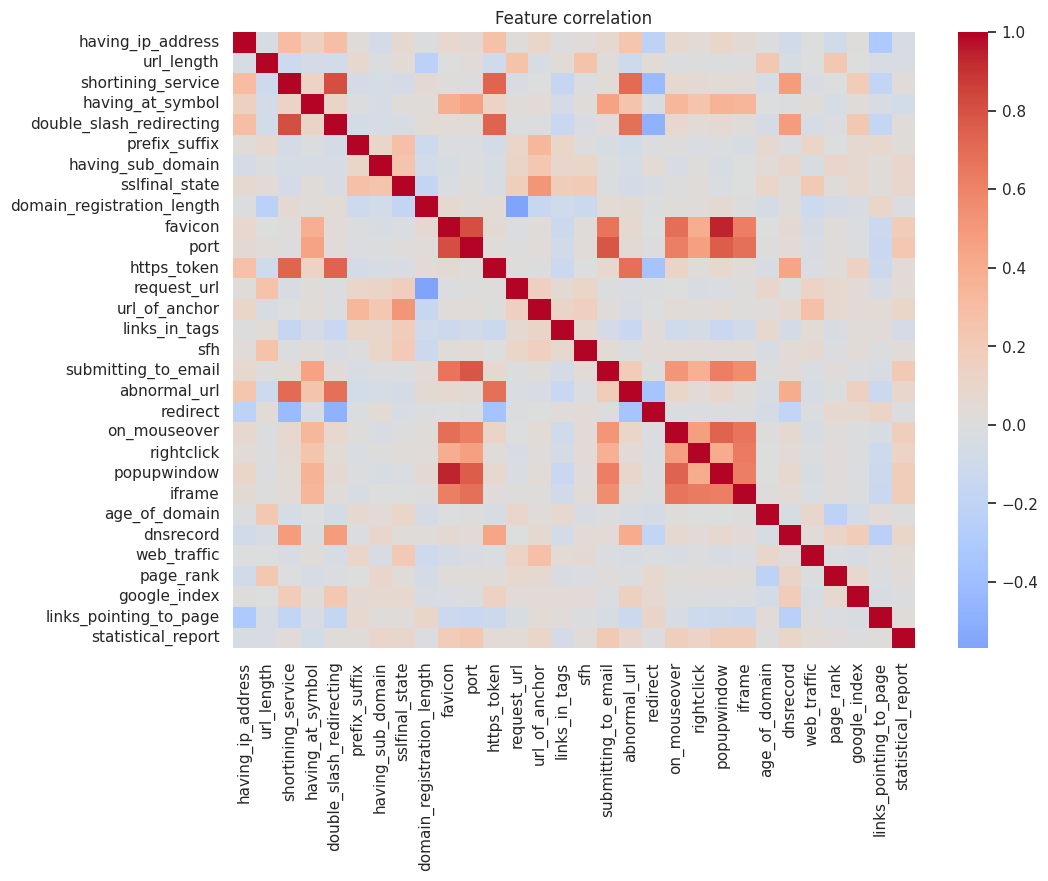

favicon             popupwindow                 0.933145
shortining_service  double_slash_redirecting    0.815809
favicon             port                        0.812657
port                submitting_to_email         0.784856
                    popupwindow                 0.754950
dtype: float64

In [3]:
c = d.drop(columns='Result').corr()
plt.figure(figsize=(11,8)); sns.heatmap(c, cmap='coolwarm', center=0); plt.title('Feature correlation'); plt.show()
pairs = c.where(np.triu(np.ones(c.shape),1).astype(bool)).stack().abs().sort_values(ascending=False).head(5); pairs

**Observation:** several features are correlated, which is the motivation for PCA and the reason Gaussian Naive Bayes (which assumes independence) struggles on raw features.